# Практическая работа 2. Двумерные массивы и изображения

Версия методички: **v2**.

В предыдущей работе использовались одномерные массивы. Здесь массив получает второе измерение:
строки и столбцы. Затем тот же двумерный массив будем интерпретировать как полутоновое изображение.

Для рисования геометрических примитивов используется **OpenCV**.

Изображения будем показывать двумя способами:

```python
Image.fromarray(img).show()       # отдельное окно системного просмотрщика
plt.imshow(img, cmap="gray", vmin=0, vmax=255)  # непосредственно в блокноте
```

`Image.show()` удобен как быстрый просмотр результата. `plt.imshow()` удобен в блокноте:
изображение остаётся рядом с кодом и пояснениями. Для полутоновых изображений явно задаём
`vmin=0`, `vmax=255`, чтобы Matplotlib не растягивал автоматически диапазон яркостей.

Основная часть работы выполняется с полутоновыми изображениями. Цвет рассматривается в конце
как короткое расширение.

Варианты самостоятельных и контрольных заданий находятся в файле
`lab02_2d_arrays_images_variants_v1.py`.

# План работы

1. Двумерный NumPy-массив: строки, столбцы, индексы.
2. Заполнение двумерного массива по формуле.
3. Двумерный массив как полутоновое изображение.
4. Пиксель: индексы массива и координаты изображения.
5. Прямоугольная область и двумерные срезы.
6. Рисование в OpenCV: линия, прямоугольник, окружность.
7. Составное изображение и отладка координат.
8. Короткое расширение: цвет, BGR и RGB.
9. Самостоятельные задания.
10. Контрольные задания.

In [1]:
import numpy as np
import cv2
from PIL import Image
import matplotlib.pyplot as plt

# 1. Двумерный NumPy-массив

Двумерный массив можно представить как таблицу. Первый индекс задаёт строку,
второй — столбец. Для NumPy используется запись `a[r, c]`.

### Пример 1. Форма массива и два индекса

**Уже изученные понятия:** `numpy_array`, `shape`, `indexing`.

**Новые понятия:** `two_dimensional_array`, `row_column_indexing`.

#### Математическая модель

Пусть массив имеет $R$ строк и $C$ столбцов:

$$A = \{a_{r,c}\}, \qquad 0 \le r < R,\quad 0 \le c < C.$$

#### Числовой пример

Для массива

$$A =
\begin{bmatrix}
1 & 2 & 3\\
4 & 5 & 6
\end{bmatrix}$$

форма равна $(2,3)$, а $a_{1,2}=6$.

#### Объяснение

`a.shape` возвращает размеры массива по его осям. Для двумерного массива:

```python
n_rows, n_cols = a.shape
```

`a[r, c]` означает элемент строки `r` и столбца `c`. Индексация начинается с нуля.

In [2]:
a = np.array([
    [1, 2, 3],
    [4, 5, 6],
])

n_rows, n_cols = a.shape

print(a)
print("shape =", a.shape)
print("n_rows =", n_rows)
print("n_cols =", n_cols)
print("a[0, 0] =", a[0, 0])
print("a[1, 2] =", a[1, 2])

[[1 2 3]
 [4 5 6]]
shape = (2, 3)
n_rows = 2
n_cols = 3
a[0, 0] = 1
a[1, 2] = 6


#### Разбор кода

1. `np.array` создаёт двумерный массив из вложенных строк.
2. `shape` содержит два числа: число строк и число столбцов.
3. Для доступа к одному элементу используются два индекса.

Проверьте без запуска: чему равны `a[0, 2]` и `a[1, 0]`?

# 2. Заполнение двумерного массива по формуле

Теперь используем знакомый цикл `for`, но один цикл будет находиться внутри другого.

### Пример 2. Матрица, заполненная собственными индексами

**Уже изученные понятия:** `for_loop`, `row_column_indexing`.

**Новые понятия:** `nested_for_loop`, `numpy_zeros`.

#### Математическая модель

$$m_{r,c} = 10r+c.$$

#### Числовой пример

Для $r=2$, $c=3$:

$$m_{2,3}=10\cdot2+3=23.$$

#### Объяснение

Внешний цикл перебирает строки `r`, внутренний — столбцы `c`.
`np.zeros((R, C))` заранее создаёт массив нужной формы.

In [3]:
n_rows, n_cols = 3, 4
m = np.zeros((n_rows, n_cols), dtype=int)

for r in range(n_rows):
    for c in range(n_cols):
        m[r, c] = 10 * r + c

print(m)

[[ 0  1  2  3]
 [10 11 12 13]
 [20 21 22 23]]


#### Разбор кода

Для каждого `r` внутренний цикл проходит все значения `c`.
Поэтому формула вычисляется для каждого элемента массива.

До запуска изменённого примера попробуйте предсказать строку с индексом `r=2`.

# 3. Двумерный массив как полутоновое изображение

Двумерный массив сам по себе является таблицей чисел. Чтобы рассматривать его как изображение,
договоримся интерпретировать каждое число как яркость одного пикселя.

### Пример 3. Чёрный холст

**Уже изученные понятия:** `two_dimensional_array`, `numpy_zeros`.

**Новые понятия:** `uint8`, `grayscale_image`, `grayscale_intensity`.

#### Математическая модель

Для полутонового изображения:

$$0 \le I_{r,c} \le 255.$$

Значение $0$ соответствует чёрному цвету, $255$ — белому.

#### Числовой пример

Значения `0`, `64`, `128`, `192`, `255` задают возрастающую яркость.

#### Объяснение

Тип `np.uint8` хранит целые числа от 0 до 255. Это естественный тип для простого
8-битного полутонового изображения.

In [4]:
H, W = 160, 240
img = np.zeros((H, W), dtype=np.uint8)

print("shape =", img.shape)
print("dtype =", img.dtype)
print("min =", img.min())
print("max =", img.max())

shape = (160, 240)
dtype = uint8
min = 0
max = 0


### Пример 4. Два способа показать изображение

**Уже изученные понятия:** `grayscale_image`, `uint8`.

**Новые понятия:** `pil_fromarray_show`, `matplotlib_imshow`.

#### Математическая модель

Пусть прямоугольная область имеет яркость $g=180$, а фон — $0$.

#### Числовой пример

В массиве размером $120\times180$ зададим светлую область строк `30:90`
и столбцов `50:130`.

#### Объяснение

`Image.fromarray(img)` создаёт объект изображения из NumPy-массива.
Метод `.show()` открывает его во внешнем просмотрщике.

`plt.imshow()` показывает тот же массив непосредственно в блокноте.
Для полутонового изображения используем `cmap="gray"`.
Параметры `vmin=0`, `vmax=255` фиксируют шкалу яркости и не позволяют Matplotlib
автоматически растягивать небольшой диапазон значений на весь чёрно-белый диапазон.

## Какой просмотрщик использовать

Для просмотра изображений в блокноте удобно использовать `plt.imshow()`, однако у такого способа есть ограничения:

* трудно сделать сетку;
* нет привычной «пипетки» для просмотра цвета отдельных пикселей;
* нельзя редактировать изображение непосредственно в окне просмотра.

`Image.show()` открывает изображение во внешнем просмотрщике, установленном в системе по умолчанию. Такой просмотрщик обычно предоставляет больше интерактивных возможностей. Например, в Windows можно использовать Paint.

По умолчанию PIL сохраняет временное изображение в формате PNG и передаёт его системному приложению, связанному с этим форматом. Чтобы изображения открывались в Paint:

1. Найдите любой PNG-файл.
2. Выберите **Открыть с помощью**.
3. Выберите **Paint**.
4. Включите **Всегда использовать это приложение для открытия PNG-файлов**.

После этого `Image.show()` будет открывать изображения в Paint, если именно Paint назначен приложением по умолчанию для PNG.


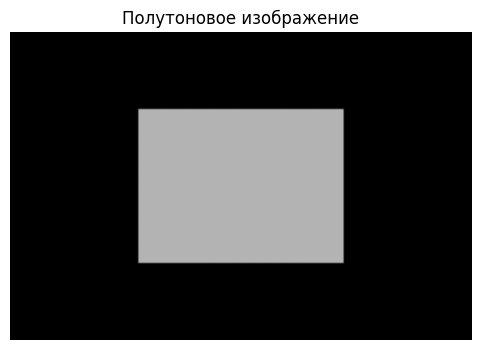

In [5]:
img = np.zeros((120, 180), dtype=np.uint8)
img[30:90, 50:130] = 180

# Быстрый просмотр во внешнем окне
Image.fromarray(img).show()

# Тот же массив непосредственно в блокноте
plt.figure(figsize=(6, 4))
plt.imshow(img, cmap="gray", vmin=0, vmax=255)
plt.title("Полутоновое изображение")
plt.axis("off")
plt.show()

#### Разбор кода

В обоих случаях исходные данные остаются одним и тем же NumPy-массивом `img`.
PIL и Matplotlib отличаются только способом отображения.

В этой работе оба способа будут использоваться параллельно:
`Image.show()` — для быстрого просмотра, `plt.imshow()` — для результата внутри блокнота.

# 4. Пиксель: индексы массива и координаты изображения

Здесь появляется важное различие. Для массива мы говорим **строка, столбец**,
а для изображения обычно используем координаты **x, y**.

### Пример 5. Один пиксель

**Уже изученные понятия:** `row_column_indexing`, `grayscale_intensity`.

**Новые понятия:** `pixel`, `image_xy_coordinates`, `array_image_coordinate_mapping`.

#### Математическая модель

Координаты изображения:

$$x = c,\qquad y = r.$$

Поэтому:

$$I(y,x) \longleftrightarrow img[y,x].$$

#### Числовой пример

Точка $(x,y)=(80,50)$ записывается в массив:

```python
img[50, 80]
```

а не `img[80, 50]`.

#### Объяснение

В изображении:
- $x$ растёт вправо;
- $y$ растёт вниз.

В NumPy:
- первый индекс — строка, то есть $y$;
- второй индекс — столбец, то есть $x$.

img[y, x] = 255


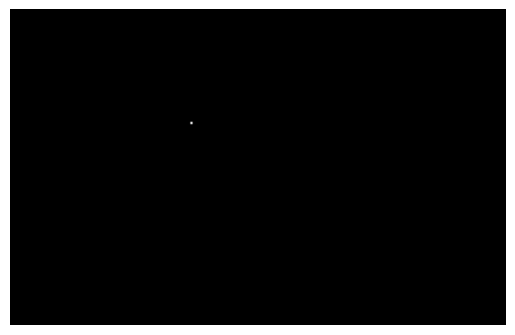

In [6]:
H, W = 140, 220
img = np.zeros((H, W), dtype=np.uint8)

x, y = 80, 50
img[y, x] = 255

print("img[y, x] =", img[y, x])
Image.fromarray(img).show()

plt.imshow(img, cmap="gray", vmin=0, vmax=255)
plt.axis("off")
plt.show()

#### Разбор кода

Эта перестановка `img[y, x]` будет использоваться далее постоянно.
Ошибка `img[x, y]` особенно неприятна для не квадратных изображений:
она может либо поставить пиксель не туда, либо привести к выходу за границы массива.

# 5. Прямоугольная область и двумерные срезы

Срез можно применять сразу по двум осям.

### Пример 6. Залитый прямоугольник средствами NumPy

**Уже изученные понятия:** `slice`, `array_image_coordinate_mapping`.

**Новое понятие:** `two_dimensional_slice`.

#### Математическая модель

Для прямоугольной области:

$$x_1 \le x \le x_2,\qquad y_1 \le y \le y_2.$$

#### Числовой пример

Пусть:

$$x_1=50,\quad y_1=30,\quad x_2=150,\quad y_2=100.$$

Тогда область массива задаётся двумя срезами:

```python
img[y1:y2+1, x1:x2+1]
```

`+1` нужен потому, что правая граница среза Python не включается.

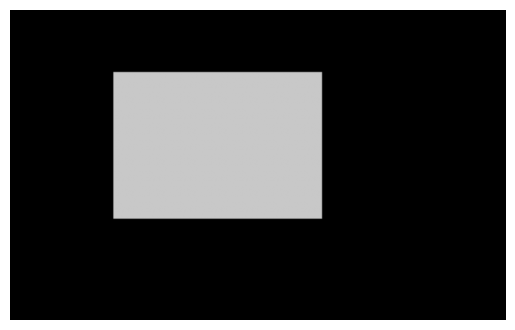

In [7]:
H, W = 150, 240
img = np.zeros((H, W), dtype=np.uint8)

x1, y1 = 50, 30
x2, y2 = 150, 100

img[y1:y2 + 1, x1:x2 + 1] = 200

Image.fromarray(img).show()

plt.imshow(img, cmap="gray", vmin=0, vmax=255)
plt.axis("off")
plt.show()

#### Разбор кода

Первый срез выбирает строки, то есть диапазон $y$.
Второй — столбцы, то есть диапазон $x$.

В следующем разделе ту же геометрическую идею будем задавать функциями OpenCV.

# 6. Рисование геометрических примитивов в OpenCV

OpenCV умеет изменять массив изображения непосредственно. Сначала создадим холст,
затем передадим его функции рисования.

### Пример 7. Отрезок

**Уже изученные понятия:** `grayscale_image`, `image_xy_coordinates`.

**Новые понятия:** `opencv_drawing`, `opencv_line`, `in_place_drawing`.

#### Математическая модель

Отрезок задаётся двумя точками:

$$A=(x_1,y_1),\qquad B=(x_2,y_2).$$

#### Числовой пример

$$A=(30,40),\qquad B=(220,130).$$

#### Объяснение

OpenCV принимает координаты точек именно в порядке `(x, y)`.
Функция `cv2.line` изменяет массив `img` непосредственно.

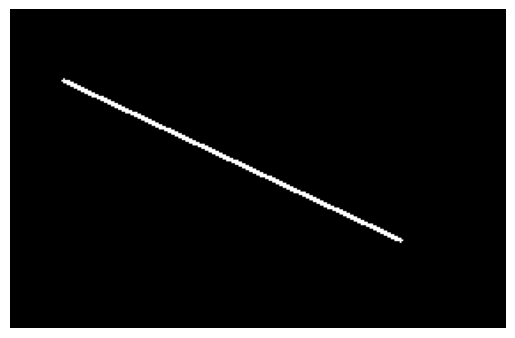

In [8]:
img = np.zeros((180, 280), dtype=np.uint8)

cv2.line(
    img,
    (30, 40),
    (220, 130),
    255,
    2,
)

Image.fromarray(img).show()

plt.imshow(img, cmap="gray", vmin=0, vmax=255)
plt.axis("off")
plt.show()

### Пример 8. Прямоугольник

**Уже изученные понятия:** `opencv_drawing`, `image_xy_coordinates`.

**Новые понятия:** `opencv_rectangle`, `drawing_thickness`.

#### Математическая модель

Прямоугольник зададим двумя противоположными углами:

$$A=(x_1,y_1),\qquad B=(x_2,y_2).$$

#### Числовой пример

$$A=(40,30),\qquad B=(190,120).$$

Толщина границы равна 3 пикселям.

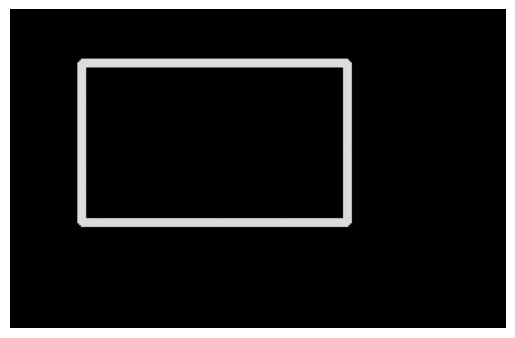

In [9]:
img = np.zeros((180, 280), dtype=np.uint8)

cv2.rectangle(
    img,
    (40, 30),
    (190, 120),
    220,
    3,
)

Image.fromarray(img).show()

plt.imshow(img, cmap="gray", vmin=0, vmax=255)
plt.axis("off")
plt.show()

### Пример 9. Окружность

**Уже изученные понятия:** `opencv_drawing`, `drawing_thickness`.

**Новое понятие:** `opencv_circle`.

#### Математическая модель

Окружность с центром $(x_0,y_0)$ и радиусом $R$:

$$(x-x_0)^2+(y-y_0)^2=R^2.$$

#### Числовой пример

$$x_0=140,\qquad y_0=90,\qquad R=45.$$

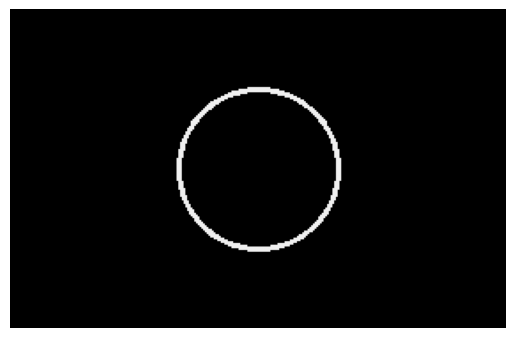

In [10]:
img = np.zeros((180, 280), dtype=np.uint8)

cv2.circle(
    img,
    (140, 90),
    45,
    240,
    2,
)

Image.fromarray(img).show()

plt.imshow(img, cmap="gray", vmin=0, vmax=255)
plt.axis("off")
plt.show()

### Пример 10. Заливка

Если `thickness=-1`, OpenCV заполняет внутреннюю область фигуры.

#### Математическая модель

Для круга закрашиваются точки, удовлетворяющие:

$$(x-x_0)^2+(y-y_0)^2 \le R^2.$$

#### Числовой пример

Создадим залитый прямоугольник яркости 160 и залитый круг яркости 230.

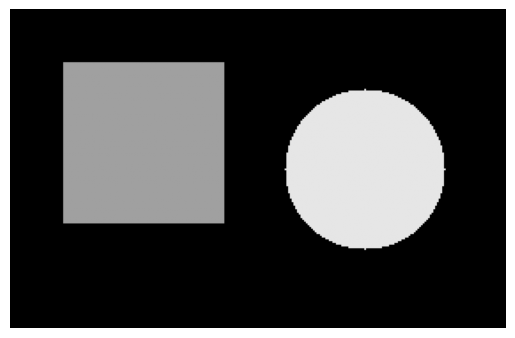

In [11]:
img = np.zeros((180, 280), dtype=np.uint8)

cv2.rectangle(img, (30, 30), (120, 120), 160, -1)
cv2.circle(img, (200, 90), 45, 230, -1)

Image.fromarray(img).show()

plt.imshow(img, cmap="gray", vmin=0, vmax=255)
plt.axis("off")
plt.show()

### Пример 11. Сравнение двух изображений через модуль разности

Здесь сравниваются два уже известных способа построить одну и ту же область.

**Новое понятие:** `absolute_difference`.

#### Математическая модель

Для каждого элемента вычислим модуль разности:

$$D_{r,c}=\left|A_{r,c}-B_{r,c}\right|.$$

Если два массива полностью совпадают, то:

$$D_{r,c}=0$$

для всех $r,c$.

Удобно проверить максимальную разность:

$$D_{\max}=\max_{r,c}D_{r,c}.$$

При полном совпадении $D_{\max}=0$.

#### Числовой пример

Если $A_{2,3}=200$, а $B_{2,3}=190$, то:

$$D_{2,3}=|200-190|=10.$$

Для изображений `uint8` удобно использовать `cv2.absdiff`:
она сразу вычисляет модуль разности без проблемы переполнения при вычитании
беззнаковых 8-битных чисел.

Максимальная разность = 0
Число различающихся пикселей = 0


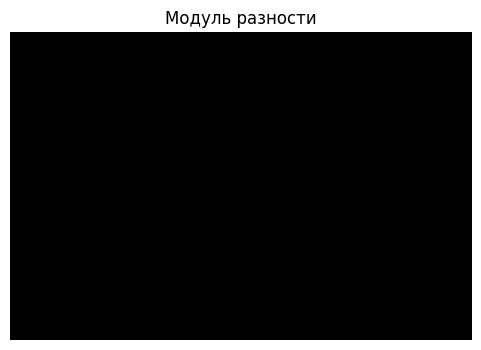

In [12]:
H, W = 160, 240
a = np.zeros((H, W), dtype=np.uint8)
b = np.zeros((H, W), dtype=np.uint8)

x1, y1, x2, y2 = 40, 30, 150, 100

a[y1:y2 + 1, x1:x2 + 1] = 200
cv2.rectangle(b, (x1, y1), (x2, y2), 200, -1)

diff = cv2.absdiff(a, b)

print("Максимальная разность =", diff.max())
print("Число различающихся пикселей =", np.count_nonzero(diff))

Image.fromarray(diff).show()

plt.figure(figsize=(6, 4))
plt.imshow(diff, cmap="gray", vmin=0, vmax=255)
plt.title("Модуль разности")
plt.axis("off")
plt.show()

#### Разбор кода

Массив `diff` сам является изображением разности.
Чёрный пиксель означает отсутствие различия, светлый — различие между результатами.

Такой способ информативнее одного логического ответа «совпадают / не совпадают»:
по изображению разности видно также, **где именно** находятся расхождения.

# 7. Составное изображение и отладка координат

Теперь объединим несколько примитивов в одном массиве.

### Пример 12. Составное изображение

**Уже изученные понятия:** `opencv_line`, `opencv_rectangle`, `opencv_circle`.

**Новое понятие:** `composite_image`.

#### Математическая модель

Изображение содержит несколько независимых геометрических объектов,
записанных в один массив $I$.

#### Числовой пример

Нарисуем линию яркости 130, прямоугольник яркости 190 и окружность яркости 250.

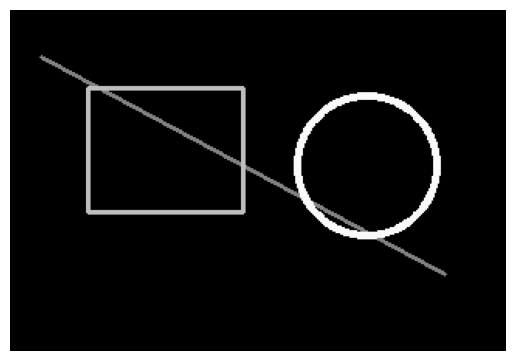

In [13]:
H, W = 220, 320
img = np.zeros((H, W), dtype=np.uint8)

cv2.line(img, (20, 30), (280, 170), 130, 2)
cv2.rectangle(img, (50, 50), (150, 130), 190, 2)
cv2.circle(img, (230, 100), 45, 250, 3)

Image.fromarray(img).show()

plt.imshow(img, cmap="gray", vmin=0, vmax=255)
plt.axis("off")
plt.show()

### Пример 13. Типичная ошибка: `img[x, y]`

**Новых понятий нет.** Используем уже изученную связь координат и индексов.

#### Математическая модель

Правильная связь:

$$r=y,\qquad c=x.$$

#### Числовой пример

При $x=150$, $y=60$ правильная запись:

```python
img[60, 150]
```

In [14]:
H, W = 120, 200
img = np.zeros((H, W), dtype=np.uint8)

x, y = 150, 60

# Неправильно:
# img[x, y] = 255

# Правильно:
img[y, x] = 255

print(img[y, x])

255


# 8. Короткое расширение: цвет

До этого каждый пиксель задавался одним числом. Для цветного изображения пиксель содержит
три числа — значения цветовых каналов.

### Пример 14. Цветное изображение OpenCV

**Уже изученные понятия:** `grayscale_image`, `shape`, `opencv_rectangle`.

**Новые понятия:** `color_image`, `bgr_rgb_order`.

#### Математическая модель

Форма цветного изображения:

$$H\times W\times 3.$$

В OpenCV тройка записывается в порядке:

$$(B,G,R).$$

#### Числовой пример

Красный цвет в OpenCV:

$$(B,G,R)=(0,0,255).$$

In [15]:
H, W = 180, 280
img_bgr = np.zeros((H, W, 3), dtype=np.uint8)

cv2.rectangle(
    img_bgr,
    (40, 30),
    (190, 120),
    (0, 0, 255),
    -1,
)

print("shape =", img_bgr.shape)

shape = (180, 280, 3)


PIL ожидает цветовые каналы в порядке RGB. Поэтому непосредственный показ BGR-массива
даст неверные цвета.

### Пример 15. BGR → RGB

**Новое понятие:** `opencv_color_conversion`.

#### Математическая модель

$$RGB=(R,G,B).$$

Нужно переставить первый и третий каналы.

#### Числовой пример

$$(0,0,255)_{BGR}\rightarrow(255,0,0)_{RGB}.$$

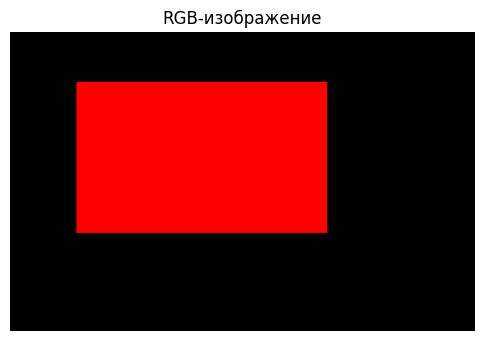

In [16]:
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

Image.fromarray(img_rgb).show()

plt.figure(figsize=(6, 4))
plt.imshow(img_rgb)
plt.title("RGB-изображение")
plt.axis("off")
plt.show()

#### Разбор кода

OpenCV остаётся библиотекой, в которой создаётся и изменяется изображение.
Перед передачей цветного массива PIL порядок каналов преобразуется из BGR в RGB.

Для полутонового изображения такой проблемы нет: у него только один канал.

# 9. Самостоятельная работа

Для каждого задания используйте строку с номером своего варианта из файла
`lab02_2d_arrays_images_variants_v1.py`.

## С1. Двумерный массив по формуле

Создайте матрицу по формуле

$$m_{r,c}=ar+c+b.$$

Выведите форму массива и несколько элементов, указанных преподавателем.

## С2. Полутоновый холст и пиксель

Создайте изображение заданного размера и фоновой яркости.
Установите пиксель с заданной яркостью в точке $(x,y)$ и покажите изображение через PIL.

## С3. Прямоугольная область

Создайте одну и ту же залитую прямоугольную область:
1. двумерным срезом NumPy;
2. `cv2.rectangle(..., thickness=-1)`.

Проверьте, совпадают ли полученные массивы.

## С4. Отрезок и окружность

На одном полутоновом изображении нарисуйте заданные отрезок и окружность.

## С5. Составное изображение

Создайте изображение, содержащее точку, отрезок, прямоугольник и окружность.
В отчёте отдельно запишите связь между $(x,y)$ и индексами массива.

## С6. Цвет OpenCV и PIL

Нарисуйте цветной прямоугольник OpenCV. Покажите его через PIL с правильным порядком каналов.

## И1. Интегральная полутоновая сцена

Создайте одно полутоновое изображение из нескольких геометрических примитивов.
Все размеры и координаты возьмите из строки своего варианта.

## И2. Интегральная отладка

Исправьте программу, в которой одновременно:
- перепутаны координаты $(x,y)$ и индексы массива;
- цветной BGR-массив передан PIL без преобразования.

# 10. Контрольные задания

Варианты приведены в отдельном файле. Номер строки таблицы равен номеру варианта.

## К1. Форма и индексация
Создать двумерный массив по формуле и определить его элементы.

## К2. Ошибка индексации
Найти и исправить ошибку `img[x,y]`.

## К3. Полутоновое изображение
Создать `uint8`-массив заданной формы и яркости фона.

## К4. Пиксель по координатам
Поставить пиксель в точке $(x,y)$ и объяснить порядок индексов.

## К5. Отрезок
Нарисовать отрезок OpenCV.

## К6. Прямоугольник
Нарисовать прямоугольник заданной толщины или заливку.

## К7. Окружность
Нарисовать окружность или круг.

## К8. Срез или OpenCV
Получить одну прямоугольную область двумя способами и сравнить массивы.

## К9. Составная сцена
Создать изображение из линии, прямоугольника и окружности.

## К10. Проверка геометрии
Определить, помещается ли фигура полностью в изображение.

## К11. Цвет BGR/RGB
Создать цветную фигуру OpenCV и корректно показать её через PIL.

## К12. Отладка цвета
Найти причину неправильного цвета и исправить программу.

# Заключение

В работе двумерный массив был последовательно рассмотрен в нескольких ролях:

$$\text{таблица чисел}
\longrightarrow
\text{матрица}
\longrightarrow
\text{полутоновое изображение}
\longrightarrow
\text{геометрическая сцена}.$$

Основные результаты:

- элемент двумерного массива задаётся двумя индексами `a[r, c]`;
- форма изображения в оттенках серого — `(H, W)`;
- координаты изображения `(x, y)` соответствуют индексам `img[y, x]`;
- OpenCV рисует непосредственно в NumPy-массиве;
- `cv2.line`, `cv2.rectangle`, `cv2.circle` используют координаты `(x, y)`;
- изображения можно просматривать через PIL и непосредственно в блокноте через `plt.imshow`;
- два результата удобно сравнивать по изображению модуля разности;
- цветное изображение OpenCV использует BGR, а PIL/Matplotlib — RGB.

В следующей работе эти массивы будут не только создаваться, но и преобразовываться:
появятся условия, маски и поэлементные операции над изображениями.